# project

*2026-11-16*

In [1]:
# Notebook equivalent of knitr::opts_chunk$set(echo = TRUE)
options(repr.plot.width = 9, repr.plot.height = 6)

In [3]:
weatherdata <- load("../data/weather.rda")

## Seasonal regression with AR(1) errors

In [4]:
dates <- seq(
  as.Date("2005-01-01"),
  as.Date("2014-12-31"),
  by = "day"
)

stopifnot(nrow(weather) == length(dates))

# Start with DTW mean temperature
temperature <- as.numeric(weather$DTW_Mean.TemperatureF)

# Annual seasonal predictors.
# Always use the same date origin for training and forecasting.
seasonal_terms <- function(dates) {
  days <- as.numeric(as.Date(dates) - as.Date("2005-01-01"))

  cbind(
    annual_sin = sin(2 * pi * days / 365.25),
    annual_cos = cos(2 * pi * days / 365.25)
  )
}

### 1. Fit seasonality + AR(1) errors using 2005–2013

In [5]:
train <- dates < as.Date("2014-01-01")

fit <- arima(
  x = temperature[train],
  order = c(1, 0, 0),
  xreg = seasonal_terms(dates[train]),
  include.mean = TRUE,
  method = "ML"
)

print(fit)


Call:
arima(x = temperature[train], order = c(1, 0, 0), xreg = seasonal_terms(dates[train]), 
    include.mean = TRUE, method = "ML")

Coefficients:
         ar1  intercept  annual_sin  annual_cos
      0.7237    51.3924     -7.8012    -23.3580
s.e.  0.0120     0.3406      0.4814      0.4807

sigma^2 estimated as 29.16:  log likelihood = -10207.39,  aic = 20424.79


### 2. Update the state with January 1–15, 2014

Keep the fitted parameters fixed.

In [6]:
available <- dates <= as.Date("2014-01-15")

updated_fit <- arima(
  x = temperature[available],
  order = c(1, 0, 0),
  xreg = seasonal_terms(dates[available]),
  include.mean = TRUE,
  fixed = unname(coef(fit)),
  transform.pars = FALSE,
  method = "ML"
)

### 3. Forecast January 16–20

In [7]:
forecast_dates <- seq(
  as.Date("2014-01-16"),
  as.Date("2014-01-20"),
  by = "day"
)

forecast <- predict(
  updated_fit,
  n.ahead = 5,
  newxreg = seasonal_terms(forecast_dates)
)

results <- data.frame(
  date = forecast_dates,
  horizon = 1:5,
  predicted = as.numeric(forecast$pred),
  actual = temperature[match(forecast_dates, dates)]
)

print(results)

# Mean squared error for these five predictions
mse <- with(results, mean((actual - predicted)^2, na.rm = TRUE))
cat("Five-day MSE:", mse, "\n")

        date horizon predicted actual
1 2014-01-16       1  26.20400     24
2 2014-01-17       2  26.34988     25
3 2014-01-18       3  26.45573     13
4 2014-01-19       4  26.53461     22
5 2014-01-20       5  26.59599     22
Five-day MSE: 45.88442 


### 4. Plot recent observations and forecasts

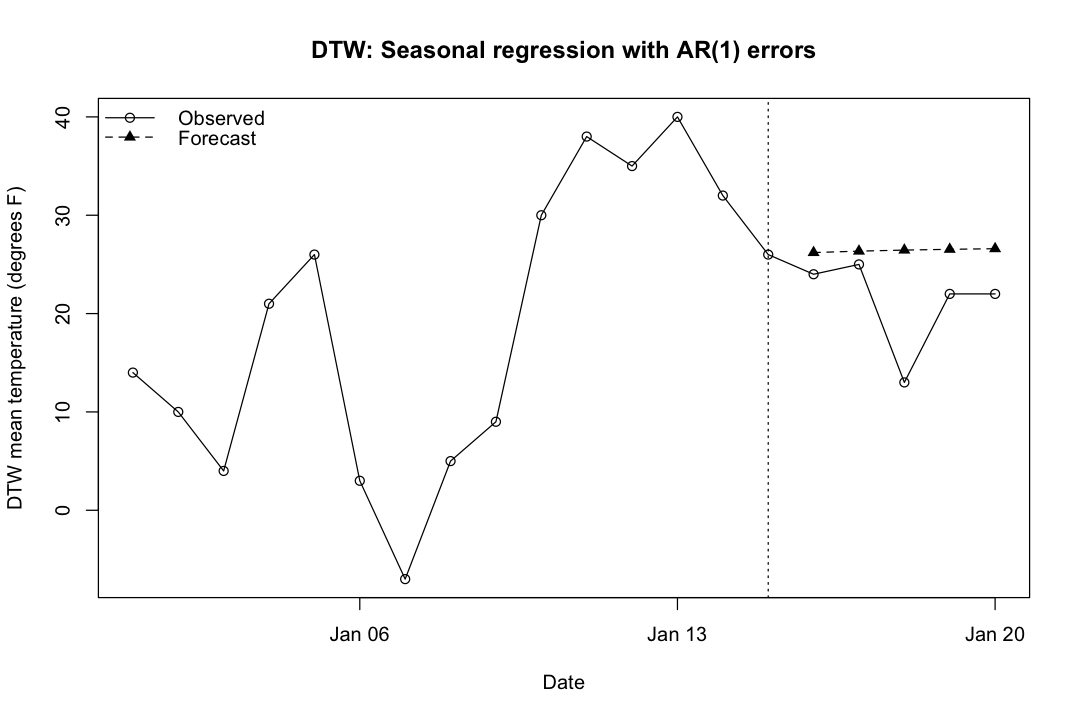

In [8]:
recent <- dates >= as.Date("2014-01-01") &
          dates <= as.Date("2014-01-20")

plot(
  dates[recent],
  temperature[recent],
  type = "o",
  xlab = "Date",
  ylab = "DTW mean temperature (degrees F)",
  main = "DTW: Seasonal regression with AR(1) errors"
)

lines(
  results$date,
  results$predicted,
  type = "o",
  lty = 2,
  pch = 17
)

abline(v = as.numeric(as.Date("2014-01-15")), lty = 3)

legend(
  "topleft",
  legend = c("Observed", "Forecast"),
  lty = c(1, 2),
  pch = c(1, 17),
  bty = "n"
)

## Original versus reduced direct-forecast models

### 1. Construct predictors observed on each forecast-origin day

In [ ]:
pressure <- as.numeric(weather$DTW_Mean.Sea.Level.PressureIn)

features <- data.frame(
  temp_now = as.numeric(weather$DTW_Mean.TemperatureF),
  dewpoint_now = as.numeric(weather$DTW_MeanDew.PointF),
  pressure_now = pressure,
  pressure_change = c(NA_real_, diff(pressure)),
  cloud_now = as.numeric(weather$DTW_CloudCover),
  wind_now = as.numeric(weather$DTW_Mean.Wind.SpeedMPH)
)

# Construct aligned training examples for a particular horizon.
# Row t contains predictors from day t and temperature from day t+h.
make_examples <- function(h) {
  origin <- seq_len(nrow(weather) - h)
  target <- origin + h

  days <- as.numeric(dates[target] - as.Date("2005-01-01"))

  data.frame(
    origin_date = dates[origin],
    target_date = dates[target],
    y = features$temp_now[target],
    annual_sin = sin(2 * pi * days / 365.25),
    annual_cos = cos(2 * pi * days / 365.25),
    features[origin, , drop = FALSE],
    row.names = NULL
  )
}

### 2. Fit original and reduced models on pre-2014 targets

In [ ]:
original_models <- vector("list", 5)
reduced_models <- vector("list", 5)

training_counts <- integer(5)

for (h in 1:5) {
  examples <- make_examples(h)

  train <- examples[
    examples$target_date < as.Date("2014-01-01"),
    ,
    drop = FALSE
  ]

  # Use identical complete training rows for both models.
  needed <- c(
    "y", "annual_sin", "annual_cos",
    "temp_now", "dewpoint_now",
    "pressure_now", "pressure_change",
    "cloud_now", "wind_now"
  )

  train <- train[
    complete.cases(train[, needed]),
    ,
    drop = FALSE
  ]

  training_counts[h] <- nrow(train)

  if (nrow(train) == 0L) {
    stop("No complete training rows for horizon ", h)
  }

  original_models[[h]] <- lm(
    y ~ annual_sin + annual_cos +
      temp_now + dewpoint_now +
      pressure_now + pressure_change +
      cloud_now + wind_now,
    data = train
  )

  # Remove dew point, wind, and cloud cover.
  reduced_models[[h]] <- lm(
    y ~ annual_sin + annual_cos +
      temp_now + pressure_now + pressure_change,
    data = train
  )
}

print(data.frame(
  horizon = 1:5,
  training_rows = training_counts
))

### 3. Evaluate monthly forecasts in held-out year 2014

In [ ]:
evaluation <- vector("list", 12)

for (month in 1:12) {
  origin_date <- as.Date(sprintf("2014-%02d-15", month))
  origin_row <- match(origin_date, dates)

  if (is.na(origin_row)) {
    stop("Missing forecast-origin date: ", origin_date)
  }

  # All horizons use the same day-15 observations.
  newdata <- features[rep(origin_row, 5), , drop = FALSE]

  target_dates <- origin_date + 1:5
  days <- as.numeric(target_dates - as.Date("2005-01-01"))

  newdata$annual_sin <- sin(2 * pi * days / 365.25)
  newdata$annual_cos <- cos(2 * pi * days / 365.25)

  original_pred <- vapply(
    1:5,
    function(h) {
      as.numeric(predict(
        original_models[[h]],
        newdata = newdata[h, , drop = FALSE]
      ))
    },
    numeric(1)
  )

  reduced_pred <- vapply(
    1:5,
    function(h) {
      as.numeric(predict(
        reduced_models[[h]],
        newdata = newdata[h, , drop = FALSE]
      ))
    },
    numeric(1)
  )

  evaluation[[month]] <- data.frame(
    origin_date = origin_date,
    target_date = target_dates,
    horizon = 1:5,
    actual = features$temp_now[match(target_dates, dates)],
    original = original_pred,
    reduced = reduced_pred
  )
}

evaluation <- do.call(rbind, evaluation)

# Score identical test cases for both models.
scored <- complete.cases(
  evaluation[, c("actual", "original", "reduced")]
)

cat(
  "Scored forecasts:", sum(scored),
  "out of", nrow(evaluation), "\n"
)

scores <- evaluation[scored, , drop = FALSE]

if (nrow(scores) == 0L) {
  stop("No complete test forecasts available.")
}

scores$original_error <- scores$actual - scores$original
scores$reduced_error <- scores$actual - scores$reduced

### 4. Overall and horizon-specific test metrics

In [ ]:
metric_summary <- function(x) {
  original_mse <- mean(x$original_error^2)
  reduced_mse <- mean(x$reduced_error^2)

  data.frame(
    n = nrow(x),
    original_MSE = original_mse,
    reduced_MSE = reduced_mse,
    original_RMSE = sqrt(original_mse),
    reduced_RMSE = sqrt(reduced_mse),
    original_MAE = mean(abs(x$original_error)),
    reduced_MAE = mean(abs(x$reduced_error)),
    MSE_improvement_pct = if (original_mse > 0) {
      100 * (original_mse - reduced_mse) / original_mse
    } else {
      NA_real_
    }
  )
}

overall <- metric_summary(scores)

by_horizon <- do.call(
  rbind,
  lapply(sort(unique(scores$horizon)), function(h) {
    data.frame(
      horizon = h,
      metric_summary(scores[scores$horizon == h, , drop = FALSE])
    )
  })
)

rownames(by_horizon) <- NULL

cat("\nOverall held-out performance:\n")
print(overall, row.names = FALSE)

cat("\nHeld-out performance by horizon:\n")
print(by_horizon, row.names = FALSE)

if (overall$reduced_MSE < overall$original_MSE) {
  cat("\nReduced model has lower test MSE on this test set.\n")
} else if (overall$reduced_MSE > overall$original_MSE) {
  cat("\nOriginal model has lower test MSE on this test set.\n")
} else {
  cat("\nThe models have equal test MSE on this test set.\n")
}

### 5. Plot test RMSE by forecast horizon

In [ ]:
matplot(
  by_horizon$horizon,
  cbind(
    by_horizon$original_RMSE,
    by_horizon$reduced_RMSE
  ),
  type = "b",
  pch = c(16, 17),
  lty = c(1, 2),
  col = c("black", "blue"),
  xlab = "Forecast horizon (days)",
  ylab = "Test RMSE (degrees F)",
  main = "Original versus reduced model"
)

legend(
  "topleft",
  legend = c("Original", "Without dew point, wind, or cloud cover"),
  col = c("black", "blue"),
  pch = c(16, 17),
  lty = c(1, 2),
  bty = "n"
)

## Model without dew point

### Fit the no-dew-point model separately for horizons 1–5

In [ ]:
no_dewpoint_models <- vector("list", 5)

for (h in 1:5) {
  examples <- make_examples(h)

  train <- examples[
    examples$target_date < as.Date("2014-01-01"),
    ,
    drop = FALSE
  ]

  # Preserve the same training rows used in your model comparisons.
  # Dew point is included in filtering, but NOT in the model.
  needed <- c(
    "y", "annual_sin", "annual_cos",
    "temp_now", "dewpoint_now",
    "pressure_now", "pressure_change",
    "cloud_now", "wind_now"
  )

  train <- train[
    complete.cases(train[, needed]),
    ,
    drop = FALSE
  ]

  if (nrow(train) == 0L) {
    stop("No complete training rows for horizon ", h)
  }

  no_dewpoint_models[[h]] <- lm(
    y ~ annual_sin + annual_cos +
      temp_now + pressure_now + pressure_change +
      cloud_now + wind_now,
    data = train
  )
}

### Inspect the one-day-ahead model

In [ ]:
summary(no_dewpoint_models[[1]])

# Coefficient estimates
coef(no_dewpoint_models[[1]])

# Coefficients, standard errors, t statistics, and p-values
coef(summary(no_dewpoint_models[[1]]))

# 95% confidence intervals
confint(no_dewpoint_models[[1]])

### Summarize model fit across all five horizons

In [ ]:
fit_statistics <- do.call(
  rbind,
  lapply(1:5, function(h) {
    model <- no_dewpoint_models[[h]]
    s <- summary(model)

    data.frame(
      horizon = h,
      training_n = nobs(model),
      multiple_R_squared = s$r.squared,
      adjusted_R_squared = s$adj.r.squared,
      residual_std_error = s$sigma
    )
  })
)

print(fit_statistics, row.names = FALSE)

# Print full summaries for all horizons
for (h in 1:5) {
  cat("\n========== Horizon:", h, "day(s) ==========\n")
  print(summary(no_dewpoint_models[[h]]))
}